In [26]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

INPUT = Path("/kaggle/input")
OUT_DIR = Path("/kaggle/working")
PRE_DIR = OUT_DIR / "ham_pretraite"          # images nettoyées
FIG_DIR = OUT_DIR / "figures"
PRE_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)

def find_file(name):
    """Cherche un fichier dans tous les inputs Kaggle (suit aussi les liens internes)."""
    for root, dirs, files in os.walk(INPUT, followlinks=True):
        if name in files:
            return Path(root) / name
    raise FileNotFoundError(f"{name} introuvable : ajoute le dataset 'ham-splits' dans Add Input")

splits_path = find_file("splits.csv")
df = pd.read_csv(splits_path)
classes = json.load(open(find_file("classes.json"), encoding="utf-8"))

# Chemin de chaque image originale (les doublons du dataset sont ignorés)
paths = {}
for root, dirs, files in os.walk(INPUT, followlinks=True):
    for f in files:
        if f.endswith(".jpg"):
            paths.setdefault(f[:-4], os.path.join(root, f))
df["path"] = df["image_id"].map(paths)

print("Split trouvé :", splits_path)
print(len(df), "images | sans fichier :", df["path"].isna().sum())
print(df["split"].value_counts().to_dict())

Split trouvé : /kaggle/input/datasets/onskallel123/ham-splits/splits.csv
10015 images | sans fichier : 0
{'train': 7002, 'val': 1532, 'test': 1481}


In [27]:
def resize_short(img, short=300):
    """Redimensionne pour que le plus petit côté fasse `short` pixels (garde les proportions)."""
    h, w = img.shape[:2]
    s = short / min(h, w)
    return cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)

_LINES = {}
def line_kernels(length=25, n_angles=12):
    """Segments droits de `length` pixels dans 12 directions (0°, 15°, 30°, ...)."""
    if (length, n_angles) not in _LINES:
        ks = []
        for a in np.arange(0, 180, 180 / n_angles):
            k = np.zeros((length, length), np.uint8); c = length // 2
            dx, dy = np.cos(np.deg2rad(a)) * c, np.sin(np.deg2rad(a)) * c
            cv2.line(k, (round(c - dx), round(c - dy)), (round(c + dx), round(c + dy)), 1, 1)
            ks.append(k)
        _LINES[(length, n_angles)] = ks
    return _LINES[(length, n_angles)]

def hair_mask(img, kernel=17, thresh=20, line_len=25, min_len=70):
    """Détecte les poils en 3 étapes :
    1) black-hat + seuillage : tout ce qui est fin et sombre ;
    2) ouverture par des segments droits orientés : on ne garde que les LIGNES
       (les points et les textures de la lésion disparaissent) ;
    3) on ne garde que les lignes assez LONGUES (>= min_len pixels)."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel, kernel))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, k)
    _, m = cv2.threshold(blackhat, thresh, 255, cv2.THRESH_BINARY)
    lines = np.zeros_like(m)
    for lk in line_kernels(line_len):
        lines = np.maximum(lines, cv2.morphologyEx(m, cv2.MORPH_OPEN, lk))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(lines, 8)
    keep = np.zeros(n, bool)
    keep[1:] = np.maximum(stats[1:, 2], stats[1:, 3]) >= min_len
    mask = keep[lab].astype(np.uint8) * 255
    return cv2.dilate(mask, np.ones((3, 3), np.uint8))   # élargit un peu pour couvrir le bord des poils

def dullrazor(img, **kw):
    """Supprime les poils : masque des poils -> inpainting. Renvoie (image nettoyée, masque)."""
    mask = hair_mask(img, **kw)
    clean = cv2.inpaint(img, mask, 5, cv2.INPAINT_TELEA)   # comble les poils avec la peau voisine
    return clean, mask

def shades_of_gray(img, p=6):
    """Normalisation des couleurs (constance des couleurs, norme de Minkowski p=6)."""
    x = img.astype(np.float32)
    norm = np.power(np.mean(np.power(x, p), axis=(0, 1)), 1 / p)
    gain = norm.mean() / (norm + 1e-6)
    return np.clip(x * gain, 0, 255).astype(np.uint8)

def read_rgb(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

def preprocess(path):
    """Pipeline complet : lecture -> redimensionnement -> poils -> couleurs."""
    img = resize_short(read_rgb(path), 300)
    img, _ = dullrazor(img)
    return shades_of_gray(img)

print("Fonctions chargées : version filtres linéaires", "line_len" in hair_mask.__code__.co_varnames)

Fonctions chargées : version filtres linéaires True


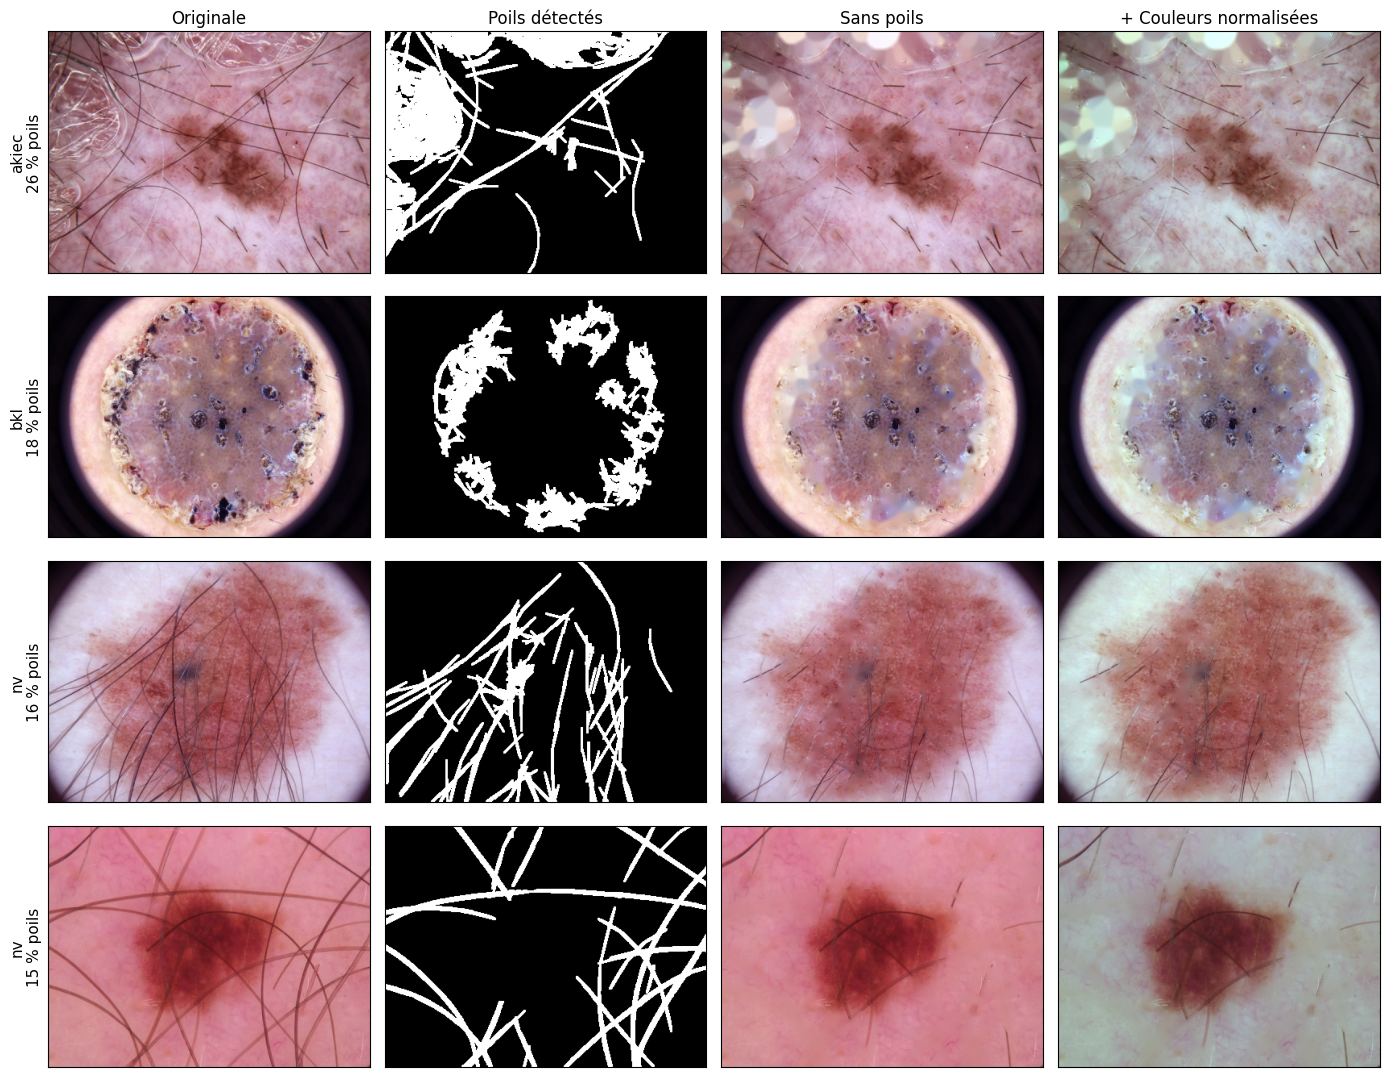

Poils détectés sur l'échantillon : médiane 0.0 %, max 26.0 %


In [28]:
# On choisit les images où le plus de poils sont détectés
sample = df.sample(300, random_state=42).copy()
sample["poils_%"] = [100 * (dullrazor(resize_short(read_rgb(p)))[1] > 0).mean() for p in sample["path"]]
hairy = sample.sort_values("poils_%", ascending=False).head(4)

titles = ["Originale", "Poils détectés", "Sans poils", "+ Couleurs normalisées"]
fig, axes = plt.subplots(4, 4, figsize=(14, 11))
for r, (_, row) in enumerate(hairy.iterrows()):
    orig = resize_short(read_rgb(row["path"]))
    clean, mask = dullrazor(orig)
    for c, im in enumerate([orig, mask, clean, shades_of_gray(clean)]):
        axes[r, c].imshow(im, cmap="gray" if im.ndim == 2 else None)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0: axes[r, c].set_title(titles[c])
    axes[r, 0].set_ylabel(f"{row['dx']}\n{row['poils_%']:.0f} % poils", fontsize=11)
plt.tight_layout(); plt.savefig(FIG_DIR / "07_dullrazor_avant_apres.png"); plt.show()

print(f"Poils détectés sur l'échantillon : médiane {sample['poils_%'].median():.1f} %, max {sample['poils_%'].max():.1f} %")

In [29]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

cv2.setNumThreads(1)          # évite que les traitements parallèles se gênent
PRE_DIR.mkdir(parents=True, exist_ok=True)

def process_and_save(item):
    image_id, path = item
    out = PRE_DIR / f"{image_id}.jpg"
    if out.exists():          # déjà fait : on passe (on peut relancer sans tout refaire)
        return
    img = preprocess(path)
    cv2.imwrite(str(out), cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 95])

todo = [(i, p) for i, p in zip(df["image_id"], df["path"]) if not (PRE_DIR / f"{i}.jpg").exists()]
print(f"Déjà faites : {len(df) - len(todo)} | restantes : {len(todo)}")

with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    list(tqdm(ex.map(process_and_save, todo), total=len(todo), desc="Prétraitement"))

n_done = len(list(PRE_DIR.glob("*.jpg")))
print("Images prétraitées :", n_done)
assert n_done == len(df), "Il manque des images : relance simplement la cellule"

Déjà faites : 10015 | restantes : 0


Prétraitement: 0it [00:00, ?it/s]

Images prétraitées : 10015


In [30]:
# Vérifie que chaque image prétraitée s'ouvre correctement
bad = [p for p in tqdm(sorted(PRE_DIR.glob("*.jpg")), desc="Vérification")
       if cv2.imread(str(p)) is None]
print("Images illisibles :", len(bad))

# S'il y en a, on les supprime et on les refait
for p in bad:
    p.unlink()
    process_and_save((p.stem, df.set_index("image_id").loc[p.stem, "path"]))
print("Images prétraitées :", len(list(PRE_DIR.glob("*.jpg"))))

Vérification:   0%|          | 0/10015 [00:00<?, ?it/s]

Images illisibles : 0
Images prétraitées : 10015


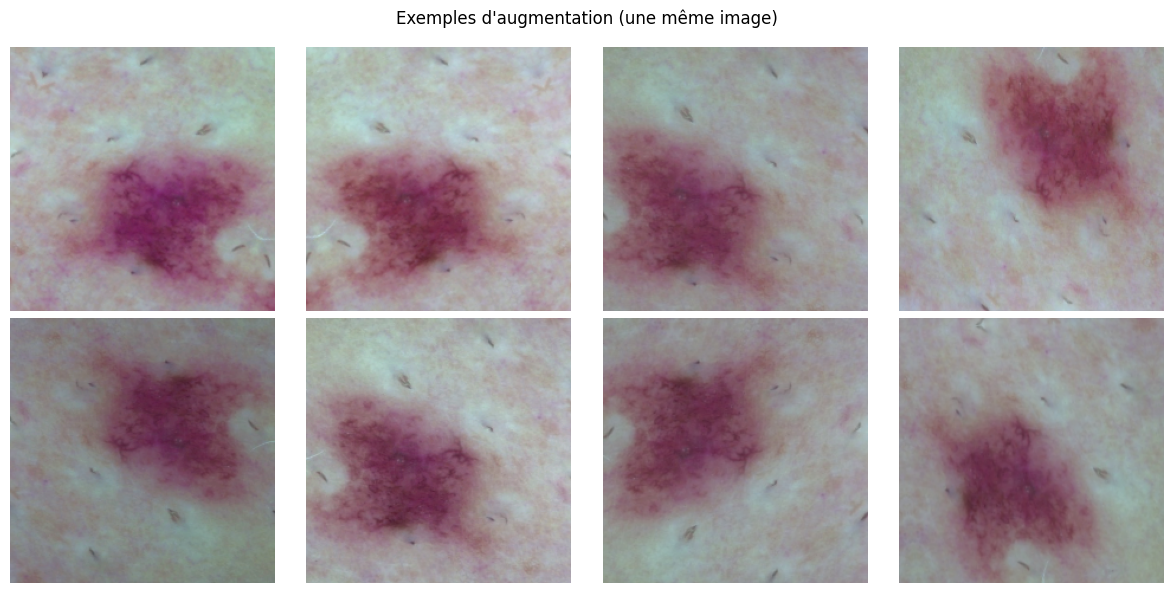

In [31]:
import albumentations as A

IMG = 224   # taille d'entrée du modèle (300 pour EfficientNet-B3)

def random_crop(size):
    try:    return A.RandomResizedCrop(size=(size, size), scale=(0.75, 1.0))   # Albumentations récent
    except TypeError: return A.RandomResizedCrop(size, size, scale=(0.75, 1.0))  # ancienne version

def rotation():
    """Rotation de -30° à +30°, coins remplis par effet miroir (pas de coins noirs)."""
    try:    return A.Affine(rotate=(-30, 30), border_mode=cv2.BORDER_REFLECT_101, p=0.5)   # Albumentations récent
    except TypeError: return A.Affine(rotate=(-30, 30), mode=cv2.BORDER_REFLECT_101, p=0.5)  # ancienne version

aug_list = [
    random_crop(IMG),
    A.HorizontalFlip(), A.VerticalFlip(), A.RandomRotate90(),
     rotation(),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.03, p=0.7),
]
train_tf = A.Compose(aug_list + [A.Normalize()])          # train : transformations aléatoires
val_tf = A.Compose([A.Resize(IMG, IMG), A.Normalize()])   # val / test : aucune transformation aléatoire

# 8 versions augmentées d'une même image (sans la normalisation, pour l'affichage)
show_tf = A.Compose(aug_list)
img = read_rgb(str(PRE_DIR / f"{df.image_id.iloc[0]}.jpg"))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    ax.imshow(show_tf(image=img)["image"]); ax.axis("off")
plt.suptitle("Exemples d'augmentation (une même image)")
plt.tight_layout(); plt.savefig(FIG_DIR / "08_augmentation.png"); plt.show()



In [32]:
%%writefile ham_dataset.py
"""Dataset HAM10000 prétraité (M1) : à importer dans le code d'entraînement.

Utilisation :
    from ham_dataset import make_loaders
    train_dl, val_dl, test_dl = make_loaders("splits.csv", "ham_pretraite", img_size=224)
"""
import cv2, numpy as np, pandas as pd, torch
import albumentations as A
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler


def _crop(size):
    try:    return A.RandomResizedCrop(size=(size, size), scale=(0.75, 1.0))
    except TypeError: return A.RandomResizedCrop(size, size, scale=(0.75, 1.0))


def _rotation():
    """Rotation de -30° à +30°, coins remplis par effet miroir (pas de coins noirs)."""
    try:    return A.Affine(rotate=(-30, 30), border_mode=cv2.BORDER_REFLECT_101, p=0.5)
    except TypeError: return A.Affine(rotate=(-30, 30), mode=cv2.BORDER_REFLECT_101, p=0.5)


def get_transforms(img_size=224):
    train = A.Compose([
        _crop(img_size), A.HorizontalFlip(), A.VerticalFlip(), A.RandomRotate90(),
        _rotation(),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.03, p=0.7),
        A.Normalize()])
    evaluation = A.Compose([A.Resize(img_size, img_size), A.Normalize()])
    return train, evaluation


class HAMDataset(Dataset):
    def __init__(self, frame, image_dir, transform):
        self.ids = frame["image_id"].tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.image_dir = str(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(f"{self.image_dir}/{self.ids[i]}.jpg"), cv2.COLOR_BGR2RGB)
        img = self.transform(image=img)["image"]                               # H x W x C
        img = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1)))   # C x H x W
        return img, self.labels[i]


def make_loaders(splits_csv, image_dir, img_size=224, batch_size=32,
                 num_workers=2, balanced=True):
    """Renvoie (train, val, test). Si balanced=True, le train est rééchantillonné
    pour que chaque classe soit vue aussi souvent (WeightedRandomSampler)."""
    df = pd.read_csv(splits_csv)
    train_tf, eval_tf = get_transforms(img_size)
    parts = {s: df[df["split"] == s] for s in ["train", "val", "test"]}

    train_ds = HAMDataset(parts["train"], image_dir, train_tf)
    if balanced:
        counts = parts["train"]["label"].value_counts()
        weights = parts["train"]["label"].map(lambda c: 1.0 / counts[c]).values
        sampler = WeightedRandomSampler(torch.DoubleTensor(weights), len(weights), replacement=True)
        train_dl = DataLoader(train_ds, batch_size, sampler=sampler, num_workers=num_workers)
    else:
        train_dl = DataLoader(train_ds, batch_size, shuffle=True, num_workers=num_workers)

    val_dl = DataLoader(HAMDataset(parts["val"], image_dir, eval_tf), batch_size, num_workers=num_workers)
    test_dl = DataLoader(HAMDataset(parts["test"], image_dir, eval_tf), batch_size, num_workers=num_workers)
    return train_dl, val_dl, test_dl

Overwriting ham_dataset.py


In [33]:
import sys, importlib, torch
from collections import Counter
sys.path.insert(0, os.getcwd())   # dossier où ham_dataset.py a été écrit
import ham_dataset; importlib.reload(ham_dataset)

train_dl, val_dl, test_dl = ham_dataset.make_loaders(splits_path, PRE_DIR, img_size=224, batch_size=32)
x, y = next(iter(train_dl))
print("Batch :", tuple(x.shape), x.dtype, "| labels :", y[:10].tolist())

# Rééquilibrage : sur 20 batchs, chaque classe doit apparaître à peu près autant
cnt = Counter()
for k, (_, yb) in enumerate(train_dl):
    cnt.update(yb.tolist())
    if k == 19: break
print("Classes vues sur 20 batchs :", {classes["codes"][c]: n for c, n in sorted(cnt.items())})
print("Batchs : train", len(train_dl), "| val", len(val_dl), "| test", len(test_dl))

Batch : (32, 3, 224, 224) torch.float32 | labels : [4, 6, 5, 1, 0, 6, 5, 6, 5, 3]
Classes vues sur 20 batchs : {'akiec': 87, 'bcc': 97, 'bkl': 88, 'df': 90, 'mel': 95, 'nv': 88, 'vasc': 95}
Batchs : train 219 | val 48 | test 47


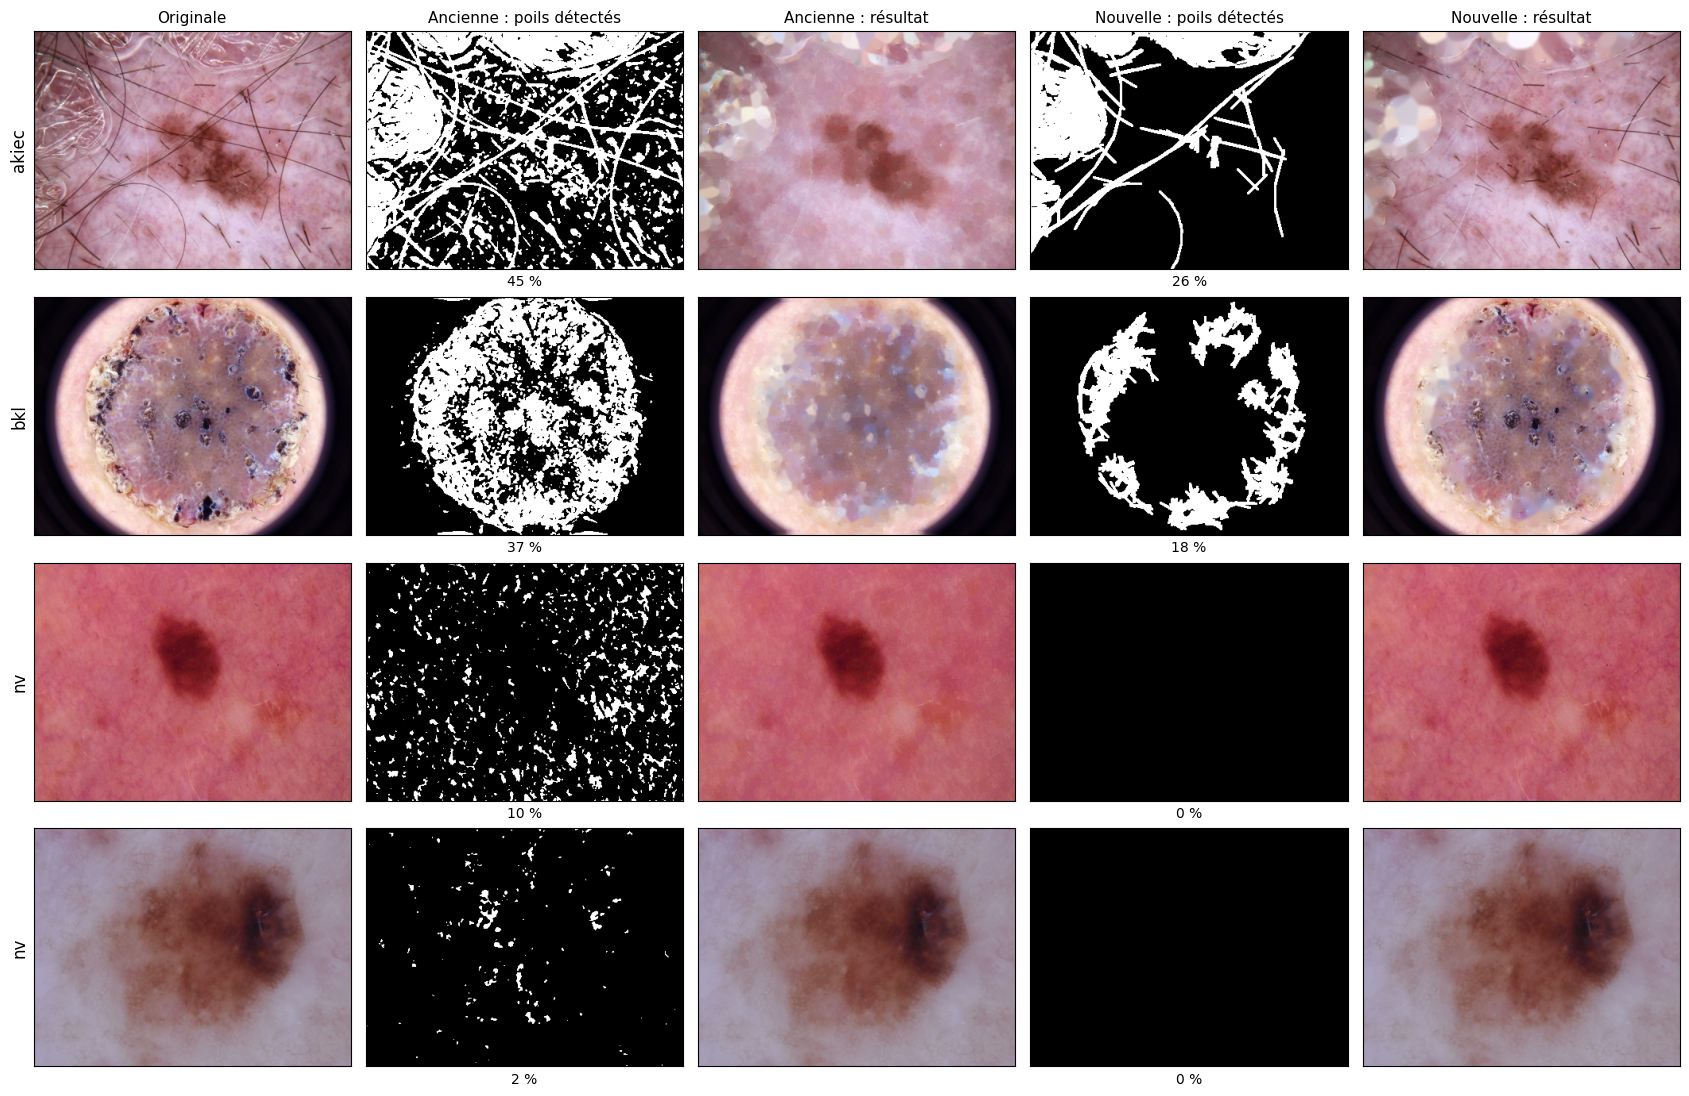

In [35]:
def dullrazor_ancien(img):
    """Version classique (avant correction), pour la comparaison du rapport."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    k = cv2.getStructuringElement(cv2.MORPH_RECT, (11, 11))
    bh = cv2.GaussianBlur(cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, k), (3, 3), 0)
    _, m = cv2.threshold(bh, 10, 255, cv2.THRESH_BINARY)
    return cv2.inpaint(img, m, 3, cv2.INPAINT_TELEA), m

# 2 images avec poils + 2 images sans poils
avec = hairy.head(2)
sans = sample[sample["poils_%"] == 0].head(2)
choix = pd.concat([avec, sans])

titres = ["Originale", "Ancienne : poils détectés", "Ancienne : résultat",
          "Nouvelle : poils détectés", "Nouvelle : résultat"]
fig, axes = plt.subplots(4, 5, figsize=(17, 11))
for r, (_, row) in enumerate(choix.iterrows()):
    orig = resize_short(read_rgb(row["path"]))
    c_old, m_old = dullrazor_ancien(orig)
    c_new, m_new = dullrazor(orig)
    for c, im in enumerate([orig, m_old, c_old, m_new, c_new]):
        axes[r, c].imshow(im, cmap="gray" if im.ndim == 2 else None)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0: axes[r, c].set_title(titres[c], fontsize=11)
    axes[r, 1].set_xlabel(f"{100*(m_old>0).mean():.0f} %"); axes[r, 3].set_xlabel(f"{100*(m_new>0).mean():.0f} %")
    axes[r, 0].set_ylabel(row["dx"], fontsize=12)
plt.tight_layout(); plt.savefig(FIG_DIR / "09_dullrazor_ancien_vs_nouveau.png"); plt.show()

In [36]:
import shutil
from IPython.display import FileLink, display
# Archive légère : ham_dataset.py + figures (les images prétraitées restent dans l'Output Kaggle)
tmp = OUT_DIR / "_livrable_S2"; tmp.mkdir(exist_ok=True)
shutil.copy("ham_dataset.py", tmp)
shutil.copytree(FIG_DIR, tmp / "figures", dirs_exist_ok=True)
shutil.make_archive(str(OUT_DIR / "resultats_M1_S2"), "zip", tmp)
shutil.rmtree(tmp)
print("Archive prête : resultats_M1_S2.zip (ham_dataset.py + figures)")
display(FileLink("resultats_M1_S2.zip"))

Archive prête : resultats_M1_S2.zip (ham_dataset.py + figures)


/kaggle/working/resultats_M1_S2.zip